In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


data = pd.read_csv('/content/fast_food_cheat_meal_workout_burn.csv')

In [2]:
data.head()

,order_id,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,...,consumer_weight_kg,fitness_level,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct,workout_shock_tier
0,FFC-00001,McDonald's,Late-Night Value Menu Binge,3,1015,47,19,117,55,32,...,96.0,Moderately Active,77.9,937.1,168.3,80.8,60.2,46.5,50.7,High Sweat Penalty
1,FFC-00002,Taco Bell,Fried Chicken Bucket & Slaw,5,1849,103,32,166,61,65,...,53.6,Moderately Active,136.7,1712.3,550.7,261.7,185.5,161.1,92.4,Extreme / Half-Marathon Toll
2,FFC-00003,Domino's Pizza,Pizza Feast & Cheesy Bread,2,1920,106,50,184,61,57,...,67.0,Moderately Active,135.0,1785.0,463.9,219.5,157.8,131.1,96.0,Extreme / Half-Marathon Toll
3,FFC-00004,McDonald's,Dessert Overload & Large Shake,2,1255,67,25,135,42,27,...,62.6,Sedentary,82.3,1172.7,351.0,166.5,120.3,103.4,62.7,Extreme / Half-Marathon Toll
4,FFC-00005,Taco Bell,Double Burger & Large Fry,4,1665,88,32,155,69,62,...,73.0,Moderately Active,127.4,1537.6,361.3,170.9,119.1,104.9,83.2,Severe Cardio Deficit


In [3]:
data.tail()

,order_id,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,...,consumer_weight_kg,fitness_level,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct,workout_shock_tier
7995,FFC-07996,Burger King,Fried Chicken Bucket & Slaw,2,1762,84,29,170,77,82,...,72.1,Highly Trained,151.5,1610.5,357.1,168.5,117.1,100.9,88.1,Severe Cardio Deficit
7996,FFC-07997,Subway,Fried Chicken Bucket & Slaw,3,2818,152,57,326,88,37,...,105.4,Sedentary,168.7,2649.3,473.2,225.5,158.5,132.1,140.9,Extreme / Half-Marathon Toll
7997,FFC-07998,Wendy's,Pizza Feast & Cheesy Bread,5,1240,63,27,126,48,43,...,114.9,Sedentary,94.7,1145.3,192.8,81.4,67.1,52.6,62.0,High Sweat Penalty
7998,FFC-07999,KFC,Fried Chicken Bucket & Slaw,4,1825,78,27,179,87,102,...,52.3,Moderately Active,173.3,1651.7,546.7,259.1,180.2,152.4,91.2,Extreme / Half-Marathon Toll
7999,FFC-08000,Burger King,Pizza Feast & Cheesy Bread,3,2891,163,65,346,95,15,...,73.7,Highly Trained,155.1,2735.9,595.1,286.4,204.6,174.9,144.6,Extreme / Half-Marathon Toll


In [4]:
data.shape

(8000, 23)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   order_id                     8000 non-null   object 
 1   fast_food_chain              8000 non-null   object 
 2   meal_category                8000 non-null   object 
 3   item_count                   8000 non-null   int64  
 4   total_calories               8000 non-null   int64  
 5   fat_grams                    8000 non-null   int64  
 6   saturated_fat_grams          8000 non-null   int64  
 7   carb_grams                   8000 non-null   int64  
 8   sugar_grams                  8000 non-null   int64  
 9   protein_grams                8000 non-null   int64  
 10  sodium_mg                    8000 non-null   int64  
 11  consumer_gender              8000 non-null   object 
 12  consumer_age                 8000 non-null   int64  
 13  consumer_weight_kg

In [7]:
data.describe()


,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,sodium_mg,consumer_age,consumer_weight_kg,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,3.502125,1602.574375,80.061375,31.985125,165.961375,62.250750,54.037250,2399.537000,41.482375,77.804587,121.555850,1481.018525,350.152287,165.043288,117.917537,100.487000,80.128575
std,1.118996,672.128080,34.288636,14.401470,70.790342,31.795058,30.690342,1072.813548,13.932712,13.929379,52.717465,622.806400,164.466555,77.544694,55.491633,47.268065,33.606582
min,2.000000,750.000000,32.000000,10.000000,66.000000,14.000000,15.000000,826.000000,18.000000,48.000000,47.100000,675.500000,100.500000,42.000000,26.300000,22.900000,37.500000
25%,2.000000,1080.000000,53.000000,21.000000,110.000000,39.000000,30.000000,1564.000000,29.000000,68.000000,79.200000,997.350000,224.875000,106.200000,76.100000,64.700000,54.000000
50%,4.000000,1479.000000,74.000000,29.000000,153.000000,55.000000,48.000000,2192.000000,42.000000,77.600000,112.200000,1366.950000,319.150000,149.950000,107.400000,91.450000,74.000000
75%,5.000000,2008.000000,100.000000,40.000000,208.000000,79.000000,71.000000,3009.250000,54.000000,87.200000,152.725000,1854.300000,439.700000,207.425000,147.500000,126.200000,100.400000
max,5.000000,3600.000000,190.000000,75.000000,380.000000,175.000000,140.000000,5800.000000,65.000000,129.400000,291.100000,3429.200000,1299.200000,614.600000,436.500000,369.500000,180.000000


In [9]:
data.min(numeric_only=True)

,0
item_count,2.0
total_calories,750.0
fat_grams,32.0
saturated_fat_grams,10.0
carb_grams,66.0
sugar_grams,14.0
protein_grams,15.0
sodium_mg,826.0
consumer_age,18.0
consumer_weight_kg,48.0


In [10]:
data.max(numeric_only=True)

,0
item_count,5.0
total_calories,3600.0
fat_grams,190.0
saturated_fat_grams,75.0
carb_grams,380.0
sugar_grams,175.0
protein_grams,140.0
sodium_mg,5800.0
consumer_age,65.0
consumer_weight_kg,129.4


In [12]:
data['net_caloric_surplus'].unique()

array([ 937.1, 1712.3, 1785. , ..., 2649.3, 1651.7, 2735.9], shape=(6286,))

In [13]:
data['fitness_level'].value_counts()

,count
fitness_level,
Sedentary,3624
Moderately Active,3172
Highly Trained,1204


In [14]:
data.duplicated().sum()

np.int64(0)

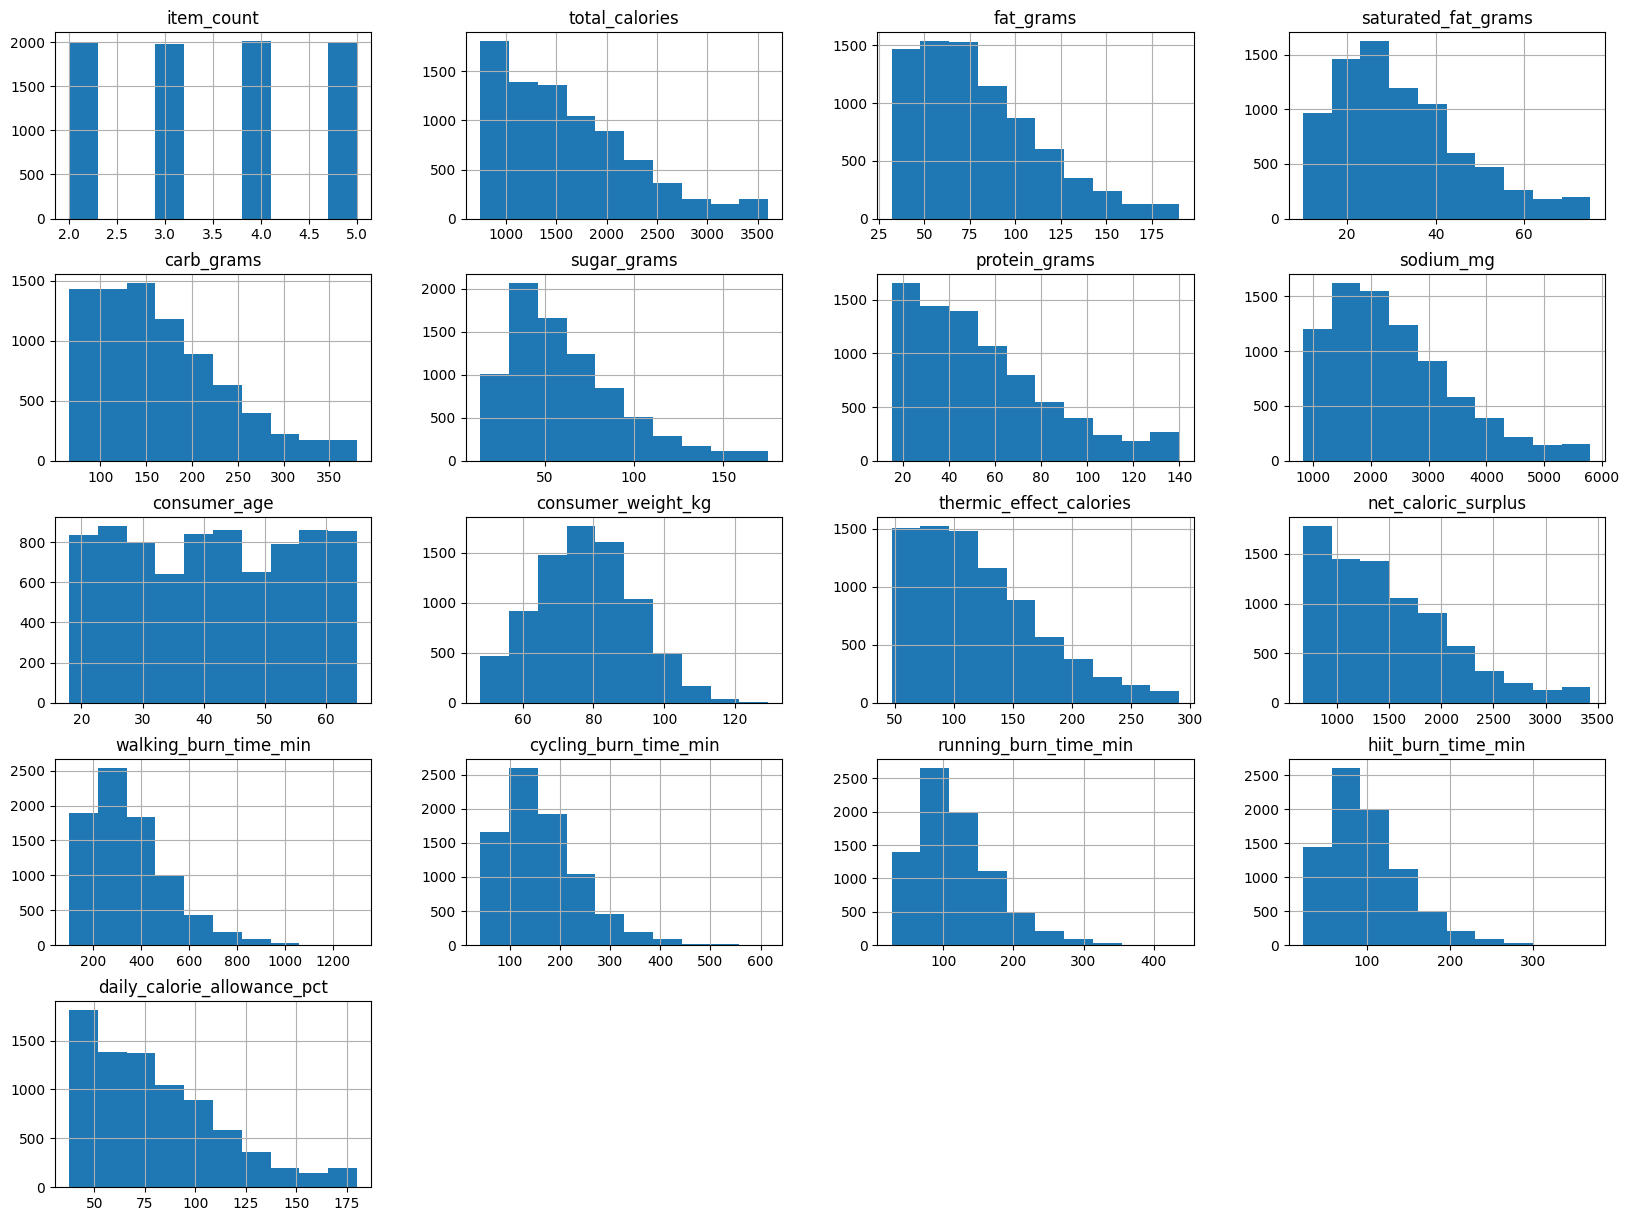

In [15]:
data.hist(figsize=(20, 15))
plt.show()